# A neural network from scratch

This notebook is how we can create a neural network only using **numpy**. This is what libraries like pytorch (we will cover later) do for you.

1. One neuron
2. Gradient descent
3. Small network with hidden layer

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

# One neuron

This is what we discussed in class. A neuron is defined as an activation function applied to wx + b, where w is the weights, and x is the inputs.

Lets code the sigmoid activation we discussed in the lecture.

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

Then lets make the neuron. It is very simple.

In [5]:
def neuron(inputs, weights, bias):
    z = np.dot(inputs, weights) + bias
    return sigmoid(z)

# Gradient descent

This is how we find the weights.
Remember we discussed learning rate and going down slopes to find the minimum?
The following is how to program this.

Let's try it on a simple hill, $\text{loss}(w) = (w - 3)^2$, whose lowest point is at $w = 3$.

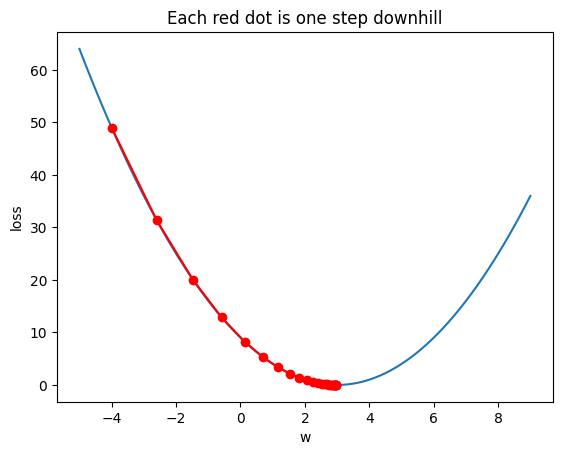

In [ ]:
def loss(w):
    return (w - 3) ** 2

def slope(w):
    return 2 * (w - 3) # This is the derivative. We use this to find the gradient. You will learn this in maths class soon.

w = -4.0 # start random
learning_rate = 0.1 # Try changing this. What happens?
history = [w]

for step in range(25):
    w = w - learning_rate * slope(w)   # step downhill
    history.append(w)

ws = np.linspace(-5, 9, 100)
plt.plot(ws, loss(ws))
plt.plot(history, [loss(h) for h in history], "ro-")
plt.xlabel("w"); plt.ylabel("loss")
plt.title("Each red dot is one step downhill")
plt.show()

# Problem that one neuron cannot solve

Lets use a dataset give in scikit-learn. If we plot it on a graph below, it will look like two moons insersecting with each other.
Since a neuron can only draw a straight line, we cannot separate this. We need a hidden layer.

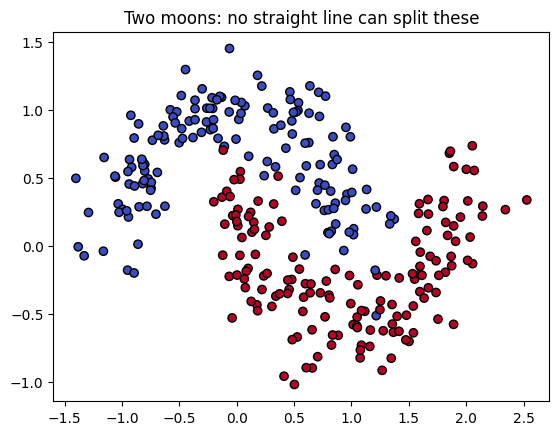

In [13]:
X, y = make_moons(n_samples=300, noise=0.2, random_state=0)
y = y.reshape(-1, 1)

# Plotting
plt.scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap="coolwarm", edgecolors="k")
plt.title("Two moons: no straight line can split these")
plt.show()

# Network

Let's make our own neural network. This is how it will be structured:
input --> hidden layer (8 neurons, tanh) --> output (sigmoid)
- W1, b1: weight and biases from input to hidden layer
- W2, b2: weight and biases from hidden layer to output

Tanh is like sigmoid, but a different activation function.

In [14]:
n_input = 2
n_hidden = 8
n_output = 1

# Random small weights
W1 = np.random.randn(n_input, n_hidden) * 0.5
b1 = np.zeros((1, n_hidden))
W2 = np.random.randn(n_hidden, n_output) * 0.5
b2 = np.zeros((1, n_output))

The @ symbol means matrix multiplication.

In [18]:
def forward(X):
    z1 = X @ W1 + b1
    a1 = np.tanh(z1)
    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)
    return a1, a2

_,predictions = forward(X) # Underscore to not make it a tuple
print("Accuracy before training:", (predictions > 0.5).mean())

Accuracy before training: 0.22666666666666666


Lets create our loss. We will use binary cross-entropy

In [19]:
def compute_loss(y_true, y_pred):
    eps = 1e-9
    return -np.mean(y_true * np.log(y_pred + eps) + (1 - y_true) * np.log(1 - y_pred + eps))

print("Loss before training:", compute_loss(y, predictions))

Loss before training: 0.7179679571805963


Now lets program the backpropagation

In [20]:
# This is chain rule from calculus. It is just the forward pass we did earlier in reverse

def backward(X, y, a1, a2):
    N = len(X)
    dz2 = (a2 - y) / N
    dW2 = a1.T @ dz2
    db2 = dz2.sum(axis=0, keepdims=True)

    da1 = dz2 @ W2.T
    dz1 = da1 * (1 - a1 ** 2)
    dW1 = X.T @ dz1
    db1 = dz1.sum(axis=0, keepdims=True)
    return dW1, db1, dW2, db2

In [22]:
learning_rate = 1.0
epochs = 3000
losses = []

for epoch in range(epochs):
    a1, a2 = forward(X)
    losses.append(compute_loss(y, a2))
    dW1, db1, dW2, db2 = backward(X, y, a1, a2)
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    if epoch % 500 == 0:
        acc = ((a2 > 0.5) == y).mean()
        print(f"epoch {epoch:4d}   loss {losses[-1]:.4f}   accuracy {acc:.2f}")

_, a2 = forward(X)
print("\nFinal accuracy:", ((a2 > 0.5) == y).mean())


epoch    0   loss 0.7180   accuracy 0.53
epoch  500   loss 0.0935   accuracy 0.97
epoch 1000   loss 0.0676   accuracy 0.98
epoch 1500   loss 0.0632   accuracy 0.98
epoch 2000   loss 0.0612   accuracy 0.98
epoch 2500   loss 0.0588   accuracy 0.99

Final accuracy: 0.9833333333333333


Lets plot what the network learned during training

In [ ]:
def plot_decision_boundary(predict_fn, X, y, title=""):
    """Colour every point on a grid by what the model predicts there."""
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = np.array(predict_fn(grid)).reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k")
    plt.title(title)
    plt.show()

plot_decision_boundary(lambda pts: (forward(pts)[1] > 0.5).astype(int), X, y.ravel(),title="Our from-scratch neural network")